In [1]:
import os

folder_path = "../02_UnStructered Files/Consumer Complaints Database"

os.listdir(folder_path)

['Consumer_Complaints.csv']

In [2]:
import pandas as pd

df = pd.read_csv(
    "../02_UnStructered Files/Consumer Complaints Database/consumer_complaints.csv"
)

df.head()

,Date received,Product,Sub-product,Issue,Sub-issue,Consumer complaint narrative,Company public response,Company,State,ZIP code,Tags,Consumer consent provided?,Submitted via,Date sent to company,Company response to consumer,Timely response?,Consumer disputed?,Complaint ID
0,3/12/2014,Mortgage,Other mortgage,"Loan modification,collection,foreclosure",NaN,NaN,NaN,M&T BANK CORPORATION,MI,48382,NaN,NaN,Referral,3/17/2014,Closed with explanation,Yes,No,759217
1,10/1/2016,Credit reporting,NaN,Incorrect information on credit report,Account status,I have outdated information on my credit repor...,Company has responded to the consumer and the ...,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",AL,352XX,NaN,Consent provided,Web,10/5/2016,Closed with explanation,Yes,No,2141773
2,10/17/2016,Consumer Loan,Vehicle loan,Managing the loan or lease,NaN,I purchased a new car on XXXX XXXX. The car de...,NaN,"CITIZENS FINANCIAL GROUP, INC.",PA,177XX,Older American,Consent provided,Web,10/20/2016,Closed with explanation,Yes,No,2163100
3,6/8/2014,Credit card,NaN,Bankruptcy,NaN,NaN,NaN,AMERICAN EXPRESS COMPANY,ID,83854,Older American,NaN,Web,6/10/2014,Closed with explanation,Yes,Yes,885638
4,9/13/2014,Debt collection,Credit card,Communication tactics,Frequent or repeated calls,NaN,NaN,"CITIBANK, N.A.",VA,23233,NaN,NaN,Web,9/13/2014,Closed with explanation,Yes,Yes,1027760


In [3]:
df.shape

(903983, 18)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 903983 entries, 0 to 903982
Data columns (total 18 columns):
 #   Column                        Non-Null Count   Dtype 
---  ------                        --------------   ----- 
 0   Date received                 903983 non-null  object
 1   Product                       903983 non-null  object
 2   Sub-product                   668823 non-null  object
 3   Issue                         903983 non-null  object
 4   Sub-issue                     426386 non-null  object
 5   Consumer complaint narrative  199970 non-null  object
 6   Company public response       257981 non-null  object
 7   Company                       903983 non-null  object
 8   State                         894758 non-null  object
 9   ZIP code                      894705 non-null  object
 10  Tags                          126038 non-null  object
 11  Consumer consent provided?    375434 non-null  object
 12  Submitted via                 903983 non-null  object
 13 

In [5]:
missing_summary = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing %": (df.isnull().sum() / len(df) * 100).round(2)
})

missing_summary.sort_values(
    "Missing %",
    ascending=False
)

,Missing Values,Missing %
Tags,777945,86.06
Consumer complaint narrative,704013,77.88
Company public response,646002,71.46
Consumer consent provided?,528549,58.47
Sub-issue,477597,52.83
Sub-product,235160,26.01
Consumer disputed?,135408,14.98
ZIP code,9278,1.03
State,9225,1.02
Date received,0,0.00


In [6]:
df["Complaint ID"].duplicated().sum()

np.int64(0)

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
id="e6n1q2"
df["Date received"] = pd.to_datetime(df["Date received"])
df["Date sent to company"] = pd.to_datetime(df["Date sent to company"])

In [9]:
id="c4p8w1"
df[["Date received", "Date sent to company"]].dtypes

Date received           datetime64[ns]
Date sent to company    datetime64[ns]
dtype: object

In [10]:
df["response_days"] = (
    df["Date sent to company"] - df["Date received"]
).dt.days

In [11]:
df["response_days"].describe()

count    903983.000000
mean          3.888063
std          16.470024
min          -1.000000
25%           0.000000
50%           0.000000
75%           3.000000
max        1962.000000
Name: response_days, dtype: float64

In [12]:
df[df["response_days"] < 0][
    ["Date received", "Date sent to company", "response_days", "Complaint ID"]
]

,Date received,Date sent to company,response_days,Complaint ID
24,2014-02-25,2014-02-24,-1,730165
271,2012-12-15,2012-12-14,-1,210633
336,2014-02-20,2014-02-19,-1,722527
576,2014-01-10,2014-01-09,-1,663076
887,2014-04-11,2014-04-10,-1,804419
...,...,...,...,...
902984,2014-01-31,2014-01-30,-1,694118
903173,2014-02-03,2014-02-02,-1,696558
903445,2013-01-16,2013-01-15,-1,236401
903752,2011-12-23,2011-12-22,-1,64708


In [13]:
df.loc[df["response_days"] < 0, "response_days"] = pd.NA

In [14]:
df["response_days"].describe()

count    896931.000000
mean          3.926495
std          16.528918
min           0.000000
25%           0.000000
50%           0.000000
75%           3.000000
max        1962.000000
Name: response_days, dtype: float64

In [15]:
df[df["response_days"] > 100][
    ["Date received", "Date sent to company", "response_days", "Complaint ID"]
].sort_values(
    "response_days",
    ascending=False
).head(20)

,Date received,Date sent to company,response_days,Complaint ID
811378,2012-04-14,2017-08-28,1962.0,31504
840013,2012-11-08,2017-08-28,1754.0,183885
806903,2012-11-09,2017-08-28,1753.0,187479
96660,2013-01-18,2017-06-19,1613.0,245755
810214,2013-04-10,2017-08-28,1601.0,379744
803240,2013-05-29,2017-08-29,1553.0,418979
827071,2013-10-25,2017-09-15,1421.0,571656
591336,2013-07-23,2017-05-18,1395.0,464190
716381,2013-08-07,2017-05-03,1365.0,495113
803471,2014-02-18,2017-08-11,1270.0,718767


In [16]:
product_complaints = (
    df["Product"]
    .value_counts()
    .head(10)
)

product_complaints

Product
Mortgage                                                                        242194
Debt collection                                                                 171567
Credit reporting                                                                140424
Credit card                                                                      89190
Bank account or service                                                          86207
Credit reporting, credit repair services, or other personal consumer reports     59186
Student loan                                                                     38612
Consumer Loan                                                                    31608
Credit card or prepaid card                                                      11921
Checking or savings account                                                       9947
Name: count, dtype: int64

In [17]:
import matplotlib.pyplot as plt

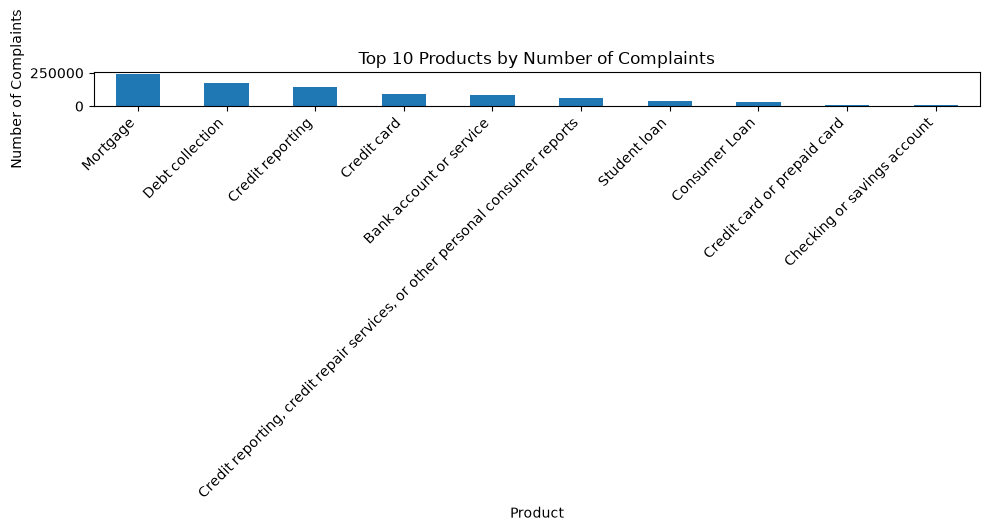

In [18]:
product_complaints.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Top 10 Products by Number of Complaints")
plt.xlabel("Product")
plt.ylabel("Number of Complaints")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [19]:
top_issues = (
    df["Issue"]
    .value_counts()
    .head(10)
)

top_issues

Issue
Loan modification,collection,foreclosure    112315
Incorrect information on credit report      102678
Loan servicing, payments, escrow account     77337
Cont'd attempts collect debt not owed        60719
Account opening, closing, or management      37963
Disclosure verification of debt              30809
Incorrect information on your report         29592
Communication tactics                        26826
Deposits and withdrawals                     22851
Dealing with my lender or servicer           17631
Name: count, dtype: int64

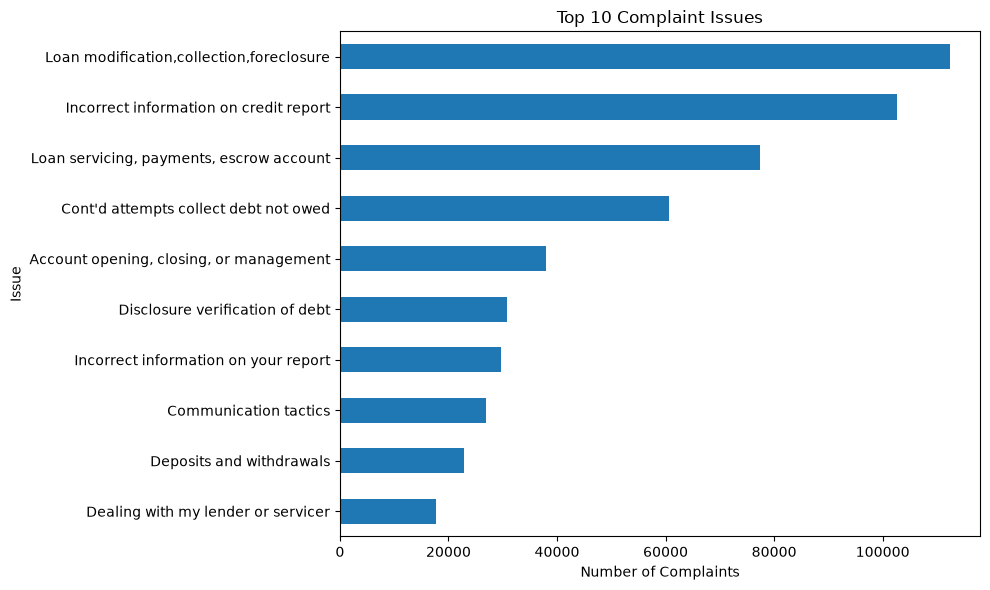

In [20]:
top_issues.sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 Complaint Issues")
plt.xlabel("Number of Complaints")
plt.ylabel("Issue")
plt.tight_layout()
plt.show()

In [21]:
product_issue = (
    df.groupby(["Product", "Issue"])
      .size()
      .reset_index(name="Complaint Count")
)

product_issue.head(10)

,Product,Issue,Complaint Count
0,Bank account or service,"Account opening, closing, or management",37963
1,Bank account or service,Deposits and withdrawals,22851
2,Bank account or service,"Making/receiving payments, sending money",7403
3,Bank account or service,Problems caused by my funds being low,11845
4,Bank account or service,Using a debit or ATM card,6145
5,Checking or savings account,Closing an account,1080
6,Checking or savings account,Credit monitoring or identity theft protection...,4
7,Checking or savings account,Improper use of your report,17
8,Checking or savings account,Incorrect information on your report,49
9,Checking or savings account,Managing an account,6026


In [22]:
product_issue_sorted = product_issue.sort_values(
    "Complaint Count",
    ascending=False
)

product_issue_sorted.head(20)

,Product,Issue,Complaint Count
150,Mortgage,"Loan modification,collection,foreclosure",112315
93,Credit reporting,Incorrect information on credit report,102678
151,Mortgage,"Loan servicing, payments, escrow account",77337
112,Debt collection,Cont'd attempts collect debt not owed,60719
0,Bank account or service,"Account opening, closing, or management",37963
113,Debt collection,Disclosure verification of debt,30809
103,"Credit reporting, credit repair services, or o...",Incorrect information on your report,28305
111,Debt collection,Communication tactics,26826
1,Bank account or service,Deposits and withdrawals,22851
213,Student loan,Dealing with my lender or servicer,17631


In [23]:
complaints_by_year = (
    df["Date received"]
    .dt.year
    .value_counts()
    .sort_index()
)

complaints_by_year

Date received
2011      2536
2012     72373
2013    108218
2014    153053
2015    168520
2016    191505
2017    207778
Name: count, dtype: int64

In [24]:
response_types = (
    df["Company response to consumer"]
    .value_counts()
)

response_types

Company response to consumer
Closed with explanation            686039
Closed with non-monetary relief    108436
Closed with monetary relief         57090
Closed without relief               17868
Closed                              17611
In progress                          7015
Closed with relief                   5304
Untimely response                    4620
Name: count, dtype: int64

In [25]:
timely_response = (
    df["Timely response?"]
    .value_counts()
)

timely_response

Timely response?
Yes    879376
No      24607
Name: count, dtype: int64

In [26]:
disputed = (
    df["Consumer disputed?"]
    .value_counts()
)

disputed

Consumer disputed?
No     620197
Yes    148378
Name: count, dtype: int64

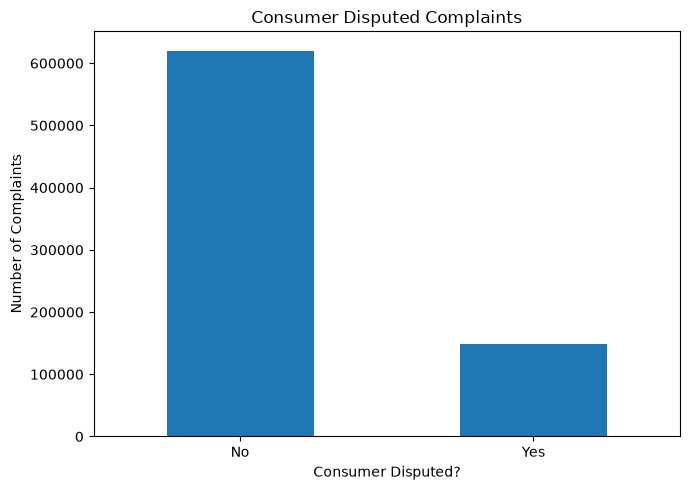

In [27]:
disputed.plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Consumer Disputed Complaints")
plt.xlabel("Consumer Disputed?")
plt.ylabel("Number of Complaints")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [28]:
dispute_response = (
    df.dropna(subset=["Consumer disputed?"])
      .groupby(["Consumer disputed?", "Company response to consumer"])
      .size()
      .reset_index(name="Complaint Count")
)

dispute_response

,Consumer disputed?,Company response to consumer,Complaint Count
0,No,Closed,13986
1,No,Closed with explanation,454879
2,No,Closed with monetary relief,45928
3,No,Closed with non-monetary relief,84311
4,No,Closed with relief,4596
5,No,Closed without relief,13057
6,No,Untimely response,3440
7,Yes,Closed,3625
8,Yes,Closed with explanation,122695
9,Yes,Closed with monetary relief,5439


In [29]:
dispute_rate = pd.crosstab(
    df["Company response to consumer"],
    df["Consumer disputed?"],
    normalize="index"
) * 100

dispute_rate

Consumer disputed?,No,Yes
Company response to consumer,,
Closed,79.416274,20.583726
Closed with explanation,78.756835,21.243165
Closed with monetary relief,89.411490,10.588510
Closed with non-monetary relief,88.367974,11.632026
Closed with relief,86.651584,13.348416
Closed without relief,73.074771,26.925229
Untimely response,99.941894,0.058106


In [30]:
state_complaints = (
    df["State"]
    .value_counts()
    .head(10)
)

state_complaints

State
CA    128373
FL     85837
TX     71751
NY     60975
GA     44664
NJ     34886
IL     33635
PA     31646
VA     28144
MD     27765
Name: count, dtype: int64

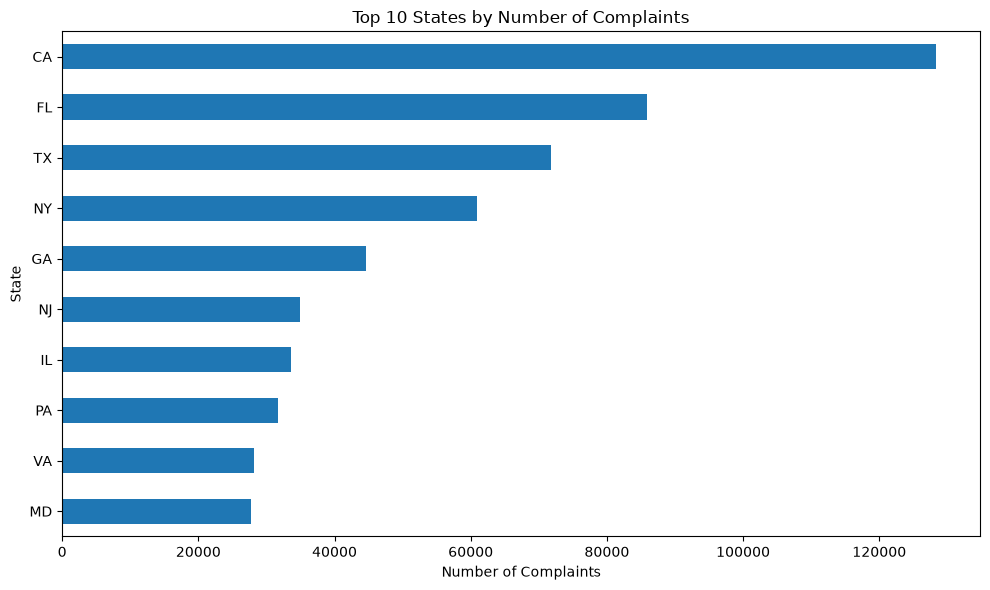

In [31]:
state_complaints.sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 States by Number of Complaints")
plt.xlabel("Number of Complaints")
plt.ylabel("State")
plt.tight_layout()
plt.show()

In [32]:
submission_method = (
    df["Submitted via"]
    .value_counts()
)

submission_method

Submitted via
Web            634850
Referral       142931
Phone           58505
Postal mail     55066
Fax             12277
Email             354
Name: count, dtype: int64

In [33]:
company_complaints = (
    df["Company"]
    .value_counts()
    .head(10)
)

company_complaints

Company
BANK OF AMERICA, NATIONAL ASSOCIATION     70488
EQUIFAX, INC.                             70341
Experian Information Solutions Inc.       59311
WELLS FARGO & COMPANY                     58440
TRANSUNION INTERMEDIATE HOLDINGS, INC.    53423
JPMORGAN CHASE & CO.                      47298
CITIBANK, N.A.                            38413
OCWEN LOAN SERVICING LLC                  25470
CAPITAL ONE FINANCIAL CORPORATION         23406
Navient Solutions, LLC.                   21829
Name: count, dtype: int64

In [34]:
top_companies = company_complaints.index

company_timely = (
    df[df["Company"].isin(top_companies)]
    .groupby(["Company", "Timely response?"])
    .size()
    .unstack(fill_value=0)
)

company_timely["Timely Response Rate (%)"] = (
    company_timely["Yes"]
    / company_timely.sum(axis=1)
    * 100
)

company_timely.sort_values(
    "Timely Response Rate (%)",
    ascending=False
)

Timely response?,No,Yes,Timely Response Rate (%)
Company,,,
"Navient Solutions, LLC.",2,21827,99.990838
Experian Information Solutions Inc.,7,59304,99.988198
"TRANSUNION INTERMEDIATE HOLDINGS, INC.",63,53360,99.882073
JPMORGAN CHASE & CO.,91,47207,99.807603
CAPITAL ONE FINANCIAL CORPORATION,66,23340,99.718021
"EQUIFAX, INC.",541,69800,99.230890
"CITIBANK, N.A.",353,38060,99.081040
OCWEN LOAN SERVICING LLC,542,24928,97.872006
"BANK OF AMERICA, NATIONAL ASSOCIATION",1570,68918,97.772671


In [35]:
id="v8n2kx"
import re
from collections import Counter

narratives = (
    df["Consumer complaint narrative"]
    .dropna()
    .astype(str)
)

words = []

for text in narratives:
    text = text.lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    
    words.extend(
        word for word in text.split()
        if len(word) > 2
    )

word_counts = Counter(words)

top_narrative_words = word_counts.most_common(20)

top_narrative_words

[('xxxx', 1875701),
 ('the', 1585988),
 ('and', 1034811),
 ('that', 604506),
 ('was', 523625),
 ('they', 462580),
 ('have', 400112),
 ('this', 388696),
 ('not', 385282),
 ('for', 379055),
 ('with', 315487),
 ('credit', 272685),
 ('account', 237585),
 ('from', 226063),
 ('had', 173438),
 ('them', 148909),
 ('loan', 143831),
 ('would', 141158),
 ('payment', 134319),
 ('are', 132019)]

In [36]:
df["Consumer complaint narrative"].dropna()

1         I have outdated information on my credit repor...
2         I purchased a new car on XXXX XXXX. The car de...
7         An account on my credit report has a mistaken ...
12        This company refuses to provide me verificatio...
16        This complaint is in regards to Square Two Fin...
                                ...                        
903975    Our son was taken to XXXX XXXX XXXX XXXX XXXX ...
903976    On XXXX/XXXX/13, without my authorization, Ban...
903979    I had an account with XXXX in XX/XX/XXXX this ...
903980    I was contacted on XX/XX/XXXX email by XXXX fr...
903982    I had a debit that was included in my chapter ...
Name: Consumer complaint narrative, Length: 199970, dtype: object

In [37]:
from nltk.corpus import stopwords

stop_words = set(stopwords.words("english"))

clean_words = [
    word
    for word in words
    if word not in stop_words
    and word != "xxxx"
]

narrative_word_counts = Counter(clean_words)

top_narrative_words = narrative_word_counts.most_common(20)

top_narrative_words

[('credit', 272685),
 ('account', 237585),
 ('loan', 143831),
 ('would', 141158),
 ('payment', 134319),
 ('bank', 116247),
 ('report', 110201),
 ('told', 107738),
 ('debt', 106933),
 ('information', 104290),
 ('received', 95634),
 ('time', 88463),
 ('company', 86639),
 ('card', 84393),
 ('called', 84353),
 ('mortgage', 81109),
 ('never', 78517),
 ('payments', 78047),
 ('pay', 76565),
 ('sent', 71527)]

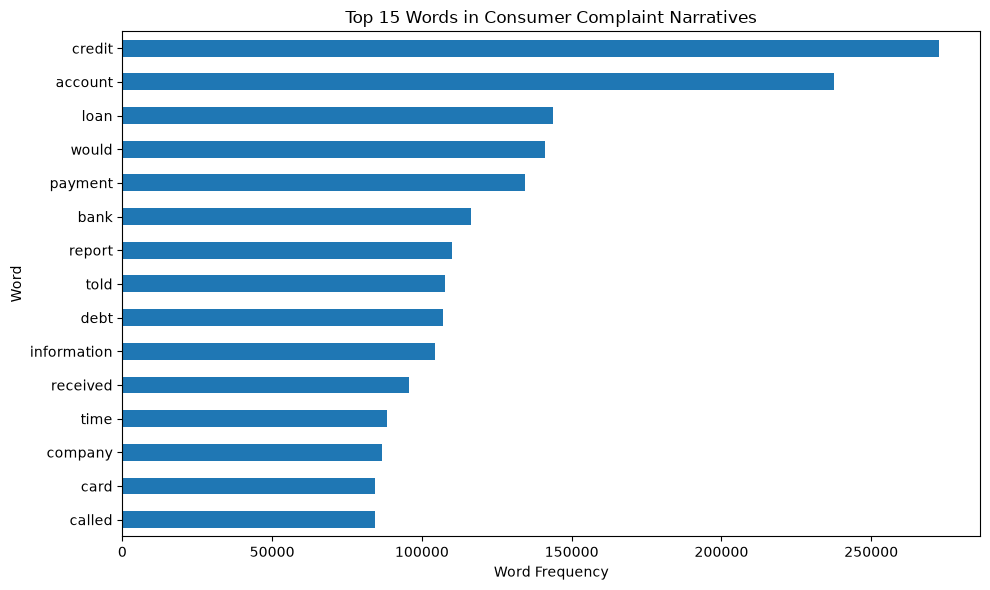

In [38]:
import pandas as pd
import matplotlib.pyplot as plt

top_words_df = pd.DataFrame(
    narrative_word_counts.most_common(15),
    columns=["Word", "Count"]
)

top_words_df = top_words_df.sort_values("Count")

top_words_df.plot(
    kind="barh",
    x="Word",
    y="Count",
    figsize=(10, 6),
    legend=False
)

plt.title("Top 15 Words in Consumer Complaint Narratives")
plt.xlabel("Word Frequency")
plt.ylabel("Word")
plt.tight_layout()
plt.show()

# Consumer Complaints Analysis — Final Summary

## Dataset Overview
- Total complaints: 903,983
- Total columns: 18
- Complaint narratives available: 199,970
- Duplicate Complaint IDs: 0
- Duplicate rows: 0

## Data Cleaning
- Converted `Date received` and `Date sent to company` to datetime.
- Created `response_days` to measure the difference between the two dates.
- Negative response-day values were treated as invalid and replaced with missing values.
- Missing values in optional fields were retained instead of artificially filling them.
- Extreme response times were retained because they represent valid observations in the dataset.

## Key Findings

### Complaint Products
The largest complaint categories were:
- Mortgage
- Debt collection
- Credit reporting
- Credit card
- Bank account or service

### Major Issues
The most common complaint issues included:
- Loan modification, collection, and foreclosure
- Incorrect information on credit reports
- Loan servicing, payments, and escrow accounts
- Attempts to collect debt that was not owed
- Account opening, closing, or management

### Complaint Trend
Complaint volume increased substantially from 2012 to 2017, with 2017 having the highest number of complaints in the dataset.

### Company Responses
The most common company response was `Closed with explanation`.

This should not automatically be interpreted as a successful resolution because the response category describes the recorded company response, not consumer satisfaction.

### Timely Responses
- Yes: 879,376 (~97.28%)
- No: 24,607 (~2.72%)

Most complaints were recorded as receiving a timely response.

### Consumer Disputes
Among complaints where dispute information was available:
- No: ~80.71%
- Yes: ~19.29%

Missing dispute values were not treated as `No`.

### Submission Method
The web was the dominant method for submitting complaints, followed by referral and phone.

### Complaint Narratives
The most frequent meaningful words included:
- credit
- account
- loan
- payment
- bank
- report
- debt
- information
- mortgage
- card

This indicates that credit reporting, accounts, lending, payments, banking, and debt were major themes in the written narratives.

## Important Interpretation Notes
- Complaint count does not represent a complaint rate because population and customer-base sizes differ.
- High complaint volume does not automatically mean a company or product performed poorly.
- Word frequency indicates common topics but does not directly measure sentiment.
- The `Timely response?` field and calculated `response_days` measure different things and should be interpreted separately.

## Overall Conclusion
The Consumer Complaints dataset shows that financial complaints were strongly concentrated around credit reporting, mortgages, debt collection, loans, payments, and account management. The analysis demonstrates how structured fields, dates, categorical variables, and unstructured complaint narratives can be combined to identify important patterns in a large real-world dataset.

In [39]:

print("Current working directory:")
print(os.getcwd())

print("\nExisting variables:")
print([name for name in globals() if name.startswith("df")])


Current working directory:
C:\Users\Kishan\OneDrive\Desktop\DataSets\Analysis

Existing variables:
['df']


In [40]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())
print("\nFirst 5 rows:")
display(df.head())

Shape: (903983, 19)

Columns:
['Date received', 'Product', 'Sub-product', 'Issue', 'Sub-issue', 'Consumer complaint narrative', 'Company public response', 'Company', 'State', 'ZIP code', 'Tags', 'Consumer consent provided?', 'Submitted via', 'Date sent to company', 'Company response to consumer', 'Timely response?', 'Consumer disputed?', 'Complaint ID', 'response_days']

First 5 rows:


,Date received,Product,Sub-product,Issue,Sub-issue,Consumer complaint narrative,Company public response,Company,State,ZIP code,Tags,Consumer consent provided?,Submitted via,Date sent to company,Company response to consumer,Timely response?,Consumer disputed?,Complaint ID,response_days
0,2014-03-12,Mortgage,Other mortgage,"Loan modification,collection,foreclosure",NaN,NaN,NaN,M&T BANK CORPORATION,MI,48382,NaN,NaN,Referral,2014-03-17,Closed with explanation,Yes,No,759217,5.0
1,2016-10-01,Credit reporting,NaN,Incorrect information on credit report,Account status,I have outdated information on my credit repor...,Company has responded to the consumer and the ...,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",AL,352XX,NaN,Consent provided,Web,2016-10-05,Closed with explanation,Yes,No,2141773,4.0
2,2016-10-17,Consumer Loan,Vehicle loan,Managing the loan or lease,NaN,I purchased a new car on XXXX XXXX. The car de...,NaN,"CITIZENS FINANCIAL GROUP, INC.",PA,177XX,Older American,Consent provided,Web,2016-10-20,Closed with explanation,Yes,No,2163100,3.0
3,2014-06-08,Credit card,NaN,Bankruptcy,NaN,NaN,NaN,AMERICAN EXPRESS COMPANY,ID,83854,Older American,NaN,Web,2014-06-10,Closed with explanation,Yes,Yes,885638,2.0
4,2014-09-13,Debt collection,Credit card,Communication tactics,Frequent or repeated calls,NaN,NaN,"CITIBANK, N.A.",VA,23233,NaN,NaN,Web,2014-09-13,Closed with explanation,Yes,Yes,1027760,0.0


In [41]:
print("Missing values:")
display(df.isnull().sum().sort_values(ascending=False).head(10))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nTimely response:")
display(df["Timely response?"].value_counts(dropna=False))

print("\nConsumer disputed:")
display(df["Consumer disputed?"].value_counts(dropna=False))

Missing values:


Tags                            777945
Consumer complaint narrative    704013
Company public response         646002
Consumer consent provided?      528549
Sub-issue                       477597
Sub-product                     235160
Consumer disputed?              135408
ZIP code                          9278
State                             9225
response_days                     7052
dtype: int64


Duplicate rows: 0

Timely response:


Timely response?
Yes    879376
No      24607
Name: count, dtype: int64


Consumer disputed:


Consumer disputed?
No     620197
Yes    148378
NaN    135408
Name: count, dtype: int64

In [42]:
df.to_csv("consumer_complaints_cleaned.csv", index=False)

print("Export completed!")
print("Rows exported:", len(df))

Export completed!
Rows exported: 903983


In [43]:
import os

csv_path = os.path.join(
    os.getcwd(),
    "consumer_complaints_cleaned.csv"
)

print("File exists:", os.path.exists(csv_path))
print("File path:", csv_path)

File exists: True
File path: C:\Users\Kishan\OneDrive\Desktop\DataSets\Analysis\consumer_complaints_cleaned.csv


In [44]:
import pandas as pd
import pyodbc

server = r"LAPTOP-79UF7QFB\SQLEXPRESS"
database = "DataAnalyticsProject"

conn = pyodbc.connect(
    "DRIVER={ODBC Driver 17 for SQL Server};"
    f"SERVER={server};"
    f"DATABASE={database};"
    "Trusted_Connection=yes;"
)

cursor = conn.cursor()
cursor.fast_executemany = True

print("Connected to SQL Server successfully!")

Connected to SQL Server successfully!


In [46]:

import pandas as pd
import numpy as np

csv_path = os.path.join(os.getcwd(), "consumer_complaints_cleaned.csv")
df_import = pd.read_csv(csv_path)

df_import = df_import.replace({np.nan: None})

columns = [
    "Complaint ID", "Date received", "Product", "Sub-product",
    "Issue", "Sub-issue", "Consumer complaint narrative",
    "Company public response", "Company", "State", "ZIP code",
    "Tags", "Consumer consent provided?", "Submitted via",
    "Date sent to company", "Company response to consumer",
    "Timely response?", "Consumer disputed?", "response_days"
]

insert_sql = """
INSERT INTO dbo.consumer_complaints_cleaned (
    [Complaint ID], [Date received], [Product], [Sub-product],
    [Issue], [Sub-issue], [Consumer complaint narrative],
    [Company public response], [Company], [State], [ZIP code],
    [Tags], [Consumer consent provided?], [Submitted via],
    [Date sent to company], [Company response to consumer],
    [Timely response?], [Consumer disputed?], [response_days]
) VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?)
"""

batch_size = 2000

for start in range(0, len(df_import), batch_size):
    batch = df_import.iloc[start:start + batch_size][columns]
    rows = [
        tuple(None if pd.isna(v) else v for v in row)
        for row in batch.itertuples(index=False, name=None)
    ]
    cursor.executemany(insert_sql, rows)
    conn.commit()
    imported = min(start + batch_size, len(df_import))
    print(f"Imported {imported:,} / {len(df_import):,}")

print("Import completed!")


Imported 2,000 / 903,983
Imported 4,000 / 903,983
Imported 6,000 / 903,983
Imported 8,000 / 903,983
Imported 10,000 / 903,983
Imported 12,000 / 903,983
Imported 14,000 / 903,983
Imported 16,000 / 903,983
Imported 18,000 / 903,983
Imported 20,000 / 903,983
Imported 22,000 / 903,983
Imported 24,000 / 903,983
Imported 26,000 / 903,983
Imported 28,000 / 903,983
Imported 30,000 / 903,983
Imported 32,000 / 903,983
Imported 34,000 / 903,983
Imported 36,000 / 903,983
Imported 38,000 / 903,983
Imported 40,000 / 903,983
Imported 42,000 / 903,983
Imported 44,000 / 903,983
Imported 46,000 / 903,983
Imported 48,000 / 903,983
Imported 50,000 / 903,983
Imported 52,000 / 903,983
Imported 54,000 / 903,983
Imported 56,000 / 903,983
Imported 58,000 / 903,983
Imported 60,000 / 903,983
Imported 62,000 / 903,983
Imported 64,000 / 903,983
Imported 66,000 / 903,983
Imported 68,000 / 903,983
Imported 70,000 / 903,983
Imported 72,000 / 903,983
Imported 74,000 / 903,983
Imported 76,000 / 903,983
Imported 78,000 